# 04 – Feature engineering

**Objectif de ce notebook :** transformer la météo brute et l'historique des feux en **signaux de risque** que le modèle pourra exploiter.

## Leçon 1 – C'est quoi une « feature » ?

En machine learning, on donne au modèle un tableau :
- chaque **ligne** est un exemple (ici : une commune × un jour) ;
- chaque **colonne** est une **feature** (une *variable explicative*) : une information qui aide à deviner la réponse ;
- une colonne spéciale est la **cible** (`feu` = 0 ou 1) : la réponse que le modèle doit apprendre à prédire.

Le modèle ne « comprend » rien à la météo. Il voit seulement des nombres et cherche des règles du type *« quand cette colonne est grande et celle-là petite, la cible vaut souvent 1 »*.

**Le feature engineering, c'est l'art de fabriquer des colonnes qui rendent ces règles faciles à trouver.**
Exemple : la pluie *d'aujourd'hui* dit peu de choses sur le risque. Mais « *ça fait 25 jours qu'il n'a pas plu* », ça, c'est un vrai signal de végétation sèche. L'information était déjà cachée dans les données, on la rend visible.

> En prévision de demande, c'est exactement la même chose : les ventes d'hier, la moyenne des 4 dernières semaines, « est-ce un jour férié ? »… sont des features que tu fabriques à partir de l'historique.

## Étape 1 – Charger et assembler les deux tables

On a deux fichiers qui partagent les mêmes clés (`code` + `jour`) :
- `table_13.csv` : la cible `feu` ;
- `meteo_13.csv` : les 5 variables météo.

On les **joint** (comme une RECHERCHEV dans Excel, mais sur deux colonnes à la fois).

Nouveauté : `parse_dates=["jour"]` demande à pandas de lire la colonne `jour` directement comme une **date** (et pas comme du texte). Indispensable pour extraire le mois, le jour de la semaine, etc.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

table = pd.read_csv("../data/processed/table_13.csv", dtype={"code": str}, parse_dates=["jour"])
meteo = pd.read_csv("../data/processed/meteo_13.csv", dtype={"code": str}, parse_dates=["jour"])

df = table.merge(meteo, on=["code", "jour"], how="left")

print(df.shape)              # attendu : (434707, 8)
print(df.isna().sum().sum()) # attendu : 0 → chaque ligne a trouvé sa météo
df.head()

(434707, 8)
0


,code,jour,feu,temperature_2m_max,relative_humidity_2m_min,wind_speed_10m_max,precipitation_sum,et0_fao_evapotranspiration
0,13001,2016-01-01,0,12.9,68,19.7,0.4,0.94
1,13001,2016-01-02,0,12.7,80,22.8,7.4,0.77
2,13001,2016-01-03,0,10.5,61,19.5,0.6,0.88
3,13001,2016-01-04,0,12.2,68,15.6,0.9,0.72
4,13001,2016-01-05,0,10.4,69,15.3,0.8,0.76


**Vérification :** même nombre de lignes qu'avant la jointure (434 707) et 0 valeur manquante. Si la jointure avait raté (par exemple un `code` lu comme nombre d'un côté et comme texte de l'autre), on aurait des `NaN` partout dans les colonnes météo.

On renomme les colonnes en noms courts et en français, pour la lisibilité :

In [2]:
df = df.rename(columns={
    "temperature_2m_max": "temp_max",
    "relative_humidity_2m_min": "humidite_min",
    "wind_speed_10m_max": "vent_max",
    "precipitation_sum": "pluie",
    "et0_fao_evapotranspiration": "evapo",
})
df.columns.tolist()

['code',
 'jour',
 'feu',
 'temp_max',
 'humidite_min',
 'vent_max',
 'pluie',
 'evapo']

## Étape 2 – Trier : une étape bête mais vitale

Beaucoup de features vont regarder **le passé** d'une commune (« la pluie des 30 derniers jours »).
Pour ça, pandas lit les lignes **dans l'ordre où elles sont**. Si le tableau n'est pas trié par commune puis par date, « les 30 lignes précédentes » ne voudraient rien dire.

`reset_index(drop=True)` renumérote les lignes 0, 1, 2… après le tri (sinon les anciens numéros restent, ce qui prête à confusion).

In [3]:
df = df.sort_values(["code", "jour"]).reset_index(drop=True)
df.head()

,code,jour,feu,temp_max,humidite_min,vent_max,pluie,evapo
0,13001,2016-01-01,0,12.9,68,19.7,0.4,0.94
1,13001,2016-01-02,0,12.7,80,22.8,7.4,0.77
2,13001,2016-01-03,0,10.5,61,19.5,0.6,0.88
3,13001,2016-01-04,0,12.2,68,15.6,0.9,0.72
4,13001,2016-01-05,0,10.4,69,15.3,0.8,0.76


## Étape 3 – Features de calendrier

Le calendrier capture deux choses :
- la **saison** (`mois`, `jour_annee`) : végétation plus sèche l'été ;
- l'**activité humaine** (`week_end`) : 90 % des feux en France sont d'origine humaine (barbecues, promenades, travaux…). Le week-end, il y a plus de monde dans les massifs.

`.dt` est la « boîte à outils dates » de pandas : `.dt.month`, `.dt.day_of_week` (0 = lundi … 6 = dimanche), `.dt.day_of_year` (1 à 366).

`(condition).astype(int)` transforme un Vrai/Faux en 1/0 – le modèle préfère les nombres.

In [4]:
df["mois"] = df["jour"].dt.month
df["jour_annee"] = df["jour"].dt.day_of_year
df["jour_semaine"] = df["jour"].dt.day_of_week
df["week_end"] = (df["jour_semaine"] >= 5).astype(int)

df[["jour", "mois", "jour_annee", "jour_semaine", "week_end"]].head(8)

,jour,mois,jour_annee,jour_semaine,week_end
0,2016-01-01,1,1,4,0
1,2016-01-02,1,2,5,1
2,2016-01-03,1,3,6,1
3,2016-01-04,1,4,0,0
4,2016-01-05,1,5,1,0
5,2016-01-06,1,6,2,0
6,2016-01-07,1,7,3,0
7,2016-01-08,1,8,4,0


## Leçon 2 – Les fenêtres glissantes (*rolling*)

Une **fenêtre glissante** calcule une statistique sur les N derniers jours, et « glisse » d'un jour à chaque ligne :

| jour | pluie | cumul 3 jours |
|---|---|---|
| 1 | 5 | 5 |
| 2 | 0 | 5 |
| 3 | 2 | 7 ← 5+0+2 |
| 4 | 0 | 2 ← 0+2+0 |

En pandas : `serie.rolling(3).sum()`.

**Piège :** notre tableau contient 119 communes à la suite. Sans précaution, la fenêtre du 1er janvier 2016 d'Aix-en-Provence irait piocher la pluie de fin 2025 de la commune précédente !
La solution : **`groupby("code")`** → on découpe le tableau par commune, on calcule la fenêtre à l'intérieur de chaque morceau, puis on recolle.

`transform(...)` applique le calcul à chaque groupe et renvoie une colonne **de la même longueur** que le tableau (pratique pour l'ajouter directement).

`lambda s: s.rolling(30, min_periods=1).sum()` est une **mini-fonction anonyme** : « pour chaque série `s` (la pluie d'une commune), fais la somme glissante sur 30 jours ».
`min_periods=1` : au tout début (les 29 premiers jours de 2016), on fait la somme de ce qu'on a au lieu de renvoyer `NaN`.

In [5]:
par_commune = df.groupby("code")

df["pluie_7j"]  = par_commune["pluie"].transform(lambda s: s.rolling(7,  min_periods=1).sum())
df["pluie_30j"] = par_commune["pluie"].transform(lambda s: s.rolling(30, min_periods=1).sum())
df["evapo_30j"] = par_commune["evapo"].transform(lambda s: s.rolling(30, min_periods=1).sum())
df["temp_max_7j"] = par_commune["temp_max"].transform(lambda s: s.rolling(7, min_periods=1).mean())

df[["code", "jour", "pluie", "pluie_7j", "pluie_30j"]].head(10)

,code,jour,pluie,pluie_7j,pluie_30j
0,13001,2016-01-01,0.4,0.4,0.4
1,13001,2016-01-02,7.4,7.8,7.8
2,13001,2016-01-03,0.6,8.4,8.4
3,13001,2016-01-04,0.9,9.3,9.3
4,13001,2016-01-05,0.8,10.1,10.1
5,13001,2016-01-06,0.9,11.0,11.0
6,13001,2016-01-07,2.4,13.4,13.4
7,13001,2016-01-08,0.0,13.0,13.4
8,13001,2016-01-09,1.2,6.8,14.6
9,13001,2016-01-10,0.0,6.2,14.6


Vérifie à la main sur les premières lignes : `pluie_7j` de la 3ᵉ ligne doit être la somme des 3 premières pluies.

### Le bilan hydrique : une feature « métier »
- `evapo_30j` = l'eau que le sol et les plantes **perdent** (évaporation + transpiration) sur 30 jours ;
- `pluie_30j` = l'eau **reçue**.

`bilan_hydrique_30j = pluie_30j − evapo_30j` : s'il est très négatif, la végétation se dessèche. C'est un indicateur proche de ce qu'utilisent les vrais indices de danger feu (comme l'IFM de Météo-France). Combiner deux colonnes avec un sens physique, c'est souvent là que le feature engineering apporte le plus.

In [6]:
df["bilan_hydrique_30j"] = df["pluie_30j"] - df["evapo_30j"]
df["bilan_hydrique_30j"].describe()

count    434707.000000
mean        -48.987735
std          85.839593
min        -259.770000
25%        -113.185000
50%         -35.560000
75%           7.680000
max         277.580000
Name: bilan_hydrique_30j, dtype: float64

## Étape 4 – « Jours depuis la dernière pluie »

C'est la feature la plus intuitive, mais aussi la plus astucieuse à coder. On considère qu'il a plu si `pluie >= 1 mm` (en dessous, ça mouille à peine la végétation).

**L'astuce en 3 temps :**
1. On marque les jours de pluie (1) et les jours secs (0).
2. On fait la **somme cumulée** de cette colonne par commune : elle augmente de 1 à chaque jour de pluie. Résultat : tous les jours entre deux pluies portent le **même numéro** → on a découpé la série en « blocs » commençant chacun par un jour de pluie.
3. Dans chaque bloc, `cumcount()` numérote les lignes 0, 1, 2, 3… → c'est exactement le nombre de jours depuis la pluie !

| pluie ≥ 1 | bloc (cumsum) | cumcount = jours sans pluie |
|---|---|---|
| 1 | 1 | 0 |
| 0 | 1 | 1 |
| 0 | 1 | 2 |
| 1 | 2 | 0 |
| 0 | 2 | 1 |

In [7]:
df["jour_de_pluie"] = (df["pluie"] >= 1).astype(int)
df["bloc"] = df.groupby("code")["jour_de_pluie"].cumsum()
df["jours_sans_pluie"] = df.groupby(["code", "bloc"]).cumcount()

# on n'a plus besoin des colonnes de travail
df = df.drop(columns=["jour_de_pluie", "bloc"])

df[["jour", "pluie", "jours_sans_pluie"]].iloc[170:200]

,jour,pluie,jours_sans_pluie
170,2016-06-19,1.4,0
171,2016-06-20,0.0,1
172,2016-06-21,0.9,2
173,2016-06-22,0.0,3
174,2016-06-23,0.0,4
175,2016-06-24,0.0,5
176,2016-06-25,0.3,6
177,2016-06-26,0.0,7
178,2016-06-27,0.0,8
179,2016-06-28,0.0,9


Regarde la sortie : le compteur monte jour après jour et retombe à 0 dès qu'il tombe ≥ 1 mm.

## Étape 5 – Vent fort

Le vent attise un départ de feu et le fait grandir avant que les pompiers n'arrivent. Dans les Bouches-du-Rhône, c'est le **mistral**.
On garde la colonne `vent_max` brute, et on ajoute un indicateur simple « vent ≥ 40 km/h » (environ 4 % des jours).

> Remarque : un modèle à base d'arbres (ce qu'on utilisera) sait trouver lui-même ce genre de seuil dans `vent_max`. Cet indicateur est donc surtout utile pour **nous** (analyse, baseline). C'est bien de le savoir : toutes les features ne servent pas autant à tous les modèles.

In [8]:
df["vent_fort"] = (df["vent_max"] >= 40).astype(int)
df["vent_fort"].mean()

np.float64(0.03841668066076691)

## Leçon 3 – La fuite de données (*data leakage*) : LE piège n°1 du ML

Une **fuite de données**, c'est quand une feature contient, sans qu'on s'en rende compte, une information **qu'on n'aurait pas eue au moment de prédire**.

Exemple absurde : la feature « nombre de feux dans la commune aujourd'hui ». Le modèle serait parfait… parce qu'on lui donne la réponse ! En production, le matin, on ne sait évidemment pas combien de feux il y aura dans la journée.

Les fuites réelles sont plus sournoises : « nombre de feux dans les 365 derniers jours » **en incluant aujourd'hui** contient la cible du jour. Le modèle aurait l'air excellent en test, puis serait mauvais dans la vraie vie.

**La règle :** pour chaque feature, se demander *« le matin du jour J, est-ce que je connais cette valeur ? »*
- Météo du jour J → **oui**, on considère qu'on dispose de la **prévision météo** du jour (c'est ce que fait Météo-France pour son indice de danger). ✅
- Feux du jour J → **non**. ❌ Il faut se limiter aux feux **jusqu'à la veille**.

L'outil pour ça : **`shift(1)`**, qui décale la série d'une ligne vers le bas → la valeur du jour J devient celle du jour J-1.

| jour | feu | feu.shift(1) |
|---|---|---|
| 1 | 0 | NaN |
| 2 | 1 | 0 |
| 3 | 0 | 1 |

## Étape 6 – Historique de feux de la commune

Certaines communes brûlent beaucoup plus que d'autres (grands massifs, routes, zones périurbaines…). On donne cette « mémoire » au modèle avec deux features, **toujours décalées d'un jour** :
- `feux_commune_365j` : nombre de jours avec feu dans la commune sur les 365 jours précédents ;
- `feux_commune_cumul` : nombre total de jours avec feu depuis 2016, jusqu'à la veille.

`fillna(0)` remplace le `NaN` créé par `shift` sur la toute première ligne de chaque commune.

In [9]:
par_commune = df.groupby("code")

df["feux_commune_365j"] = par_commune["feu"].transform(
    lambda s: s.shift(1).rolling(365, min_periods=1).sum()
).fillna(0)

df["feux_commune_cumul"] = par_commune["feu"].transform(
    lambda s: s.shift(1).cumsum()
).fillna(0)

# Vérification sur Marseille : le compteur doit augmenter le LENDEMAIN d'un feu, pas le jour même
marseille = df[df["code"] == "13055"]
marseille[["jour", "feu", "feux_commune_cumul"]].iloc[185:195]

,jour,feu,feux_commune_cumul
197447,2016-07-04,0,1.0
197448,2016-07-05,0,1.0
197449,2016-07-06,0,1.0
197450,2016-07-07,0,1.0
197451,2016-07-08,1,1.0
197452,2016-07-09,0,2.0
197453,2016-07-10,0,2.0
197454,2016-07-11,0,2.0
197455,2016-07-12,0,2.0
197456,2016-07-13,0,2.0


Dans la sortie, repère une ligne avec `feu = 1` : `feux_commune_cumul` ne change **pas** sur cette ligne, il augmente à la ligne **suivante**. C'est la preuve qu'il n'y a pas de fuite.

**Limite à connaître :** en 2016, ces compteurs partent de zéro (on n'a pas de données avant). Le modèle verra donc des historiques « trop faibles » la première année. C'est une limite à mentionner dans le README.

## Étape 7 – Activité de feux dans le département la veille

Quand plusieurs feux ont démarré dans le département la veille, c'est souvent que les conditions sont dangereuses partout (sécheresse, vent). C'est un signal **régional** qui complète la météo locale.

On compte les feux de **tout le département** chaque jour (`groupby("jour")`), on décale d'un jour (`shift(1)`, toujours la règle anti-fuite), puis on rattache cette valeur à chaque commune.

In [10]:
feux_par_jour = df.groupby("jour")["feu"].sum()
feux_dept_veille = feux_par_jour.shift(1).fillna(0).rename("feux_dept_veille")

df = df.merge(feux_dept_veille, left_on="jour", right_index=True, how="left")
df[["jour", "code", "feux_dept_veille"]].head()

,jour,code,feux_dept_veille
0,2016-01-01,13001,0.0
1,2016-01-02,13001,0.0
2,2016-01-03,13001,0.0
3,2016-01-04,13001,0.0
4,2016-01-05,13001,0.0


## Étape 8 – Est-ce que nos features ont du signal ?

Avant de donner les features au modèle, on vérifie qu'elles sont **liées à la cible**. Méthode simple et très puissante :
1. on range une feature en **tranches** (`pd.cut`) ;
2. pour chaque tranche, on calcule la **moyenne de `feu`** = le **taux de feu** (puisque `feu` vaut 0 ou 1, sa moyenne est la proportion de 1).

Si le taux monte (ou descend) nettement d'une tranche à l'autre, la feature est informative.

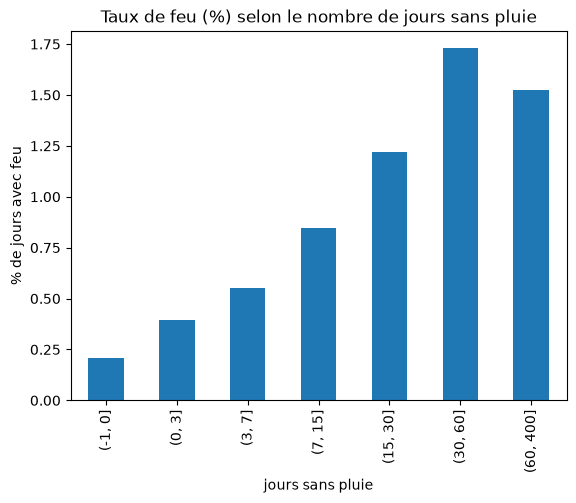

jours_sans_pluie
(-1, 0]      0.205748
(0, 3]       0.393923
(3, 7]       0.553094
(7, 15]      0.847973
(15, 30]     1.222269
(30, 60]     1.728684
(60, 400]    1.526718
Name: feu, dtype: float64

In [11]:
tranches = pd.cut(df["jours_sans_pluie"], bins=[-1, 0, 3, 7, 15, 30, 60, 400])
taux = df.groupby(tranches, observed=True)["feu"].mean() * 100

taux.plot(kind="bar", title="Taux de feu (%) selon le nombre de jours sans pluie")
plt.ylabel("% de jours avec feu")
plt.xlabel("jours sans pluie")
plt.show()
taux

**Lecture :** les jours de pluie, on a environ 0,2 % de jours avec feu. Après plus de 30 jours secs, on dépasse 1,5 % : **le risque est multiplié par environ 8**. La feature est très informative.

Fais la même chose pour l'historique de la commune et l'activité de la veille :

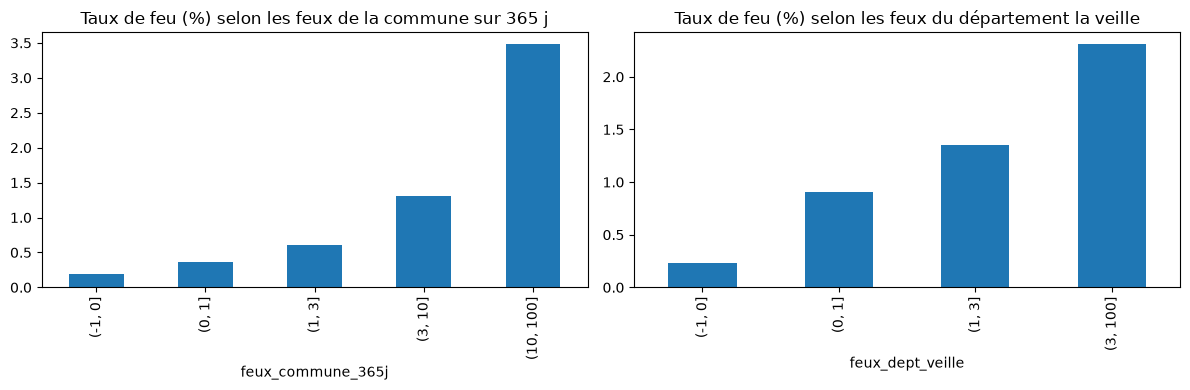

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

t1 = pd.cut(df["feux_commune_365j"], bins=[-1, 0, 1, 3, 10, 100])
(df.groupby(t1, observed=True)["feu"].mean() * 100).plot(kind="bar", ax=axes[0],
    title="Taux de feu (%) selon les feux de la commune sur 365 j")

t2 = pd.cut(df["feux_dept_veille"], bins=[-1, 0, 1, 3, 100])
(df.groupby(t2, observed=True)["feu"].mean() * 100).plot(kind="bar", ax=axes[1],
    title="Taux de feu (%) selon les feux du département la veille")

plt.tight_layout()
plt.show()

`plt.subplots(1, 2)` crée une figure avec 1 ligne et 2 graphiques côte à côte ; `ax=axes[0]` dit « dessine dans le premier ».

**À toi de jouer :** refais l'analyse en tranches pour `vent_fort`, `week_end` et `bilan_hydrique_30j`. Lesquelles ont le plus de signal ? (Indice : pour `vent_fort` et `week_end`, pas besoin de `pd.cut`, ils valent déjà 0 ou 1 → `df.groupby("vent_fort")["feu"].mean()`.)

In [13]:
# à toi : vent_fort, week_end, bilan_hydrique_30j

## Étape 9 – Sauvegarder

On sauvegarde la table complète : c'est l'entrée des prochains notebooks (baseline, puis modèle).

In [14]:
print(df.shape)
df.to_csv("../data/processed/features_13.csv", index=False)

(434707, 22)


## Récap du notebook

| Feature | Idée | Anti-fuite ? |
|---|---|---|
| `mois`, `jour_annee` | saison | — |
| `jour_semaine`, `week_end` | activité humaine | — |
| `temp_max`, `humidite_min`, `vent_max`, `pluie`, `evapo` | météo du jour (= prévision) | météo prévue le matin |
| `pluie_7j`, `pluie_30j`, `temp_max_7j` | conditions récentes | fenêtres glissantes par commune |
| `bilan_hydrique_30j` | sécheresse de la végétation | — |
| `jours_sans_pluie` | dessèchement | — |
| `vent_fort` | propagation | — |
| `feux_commune_365j`, `feux_commune_cumul` | commune « à risque » | `shift(1)` |
| `feux_dept_veille` | conditions régionales dangereuses | `shift(1)` |

**Les 3 notions clés à retenir :**
1. **Feature** = colonne qui aide à prédire ; le feature engineering rend visible une information cachée.
2. **`groupby` + `rolling` / `cumsum`** = calculs sur le passé, commune par commune.
3. **Fuite de données** = utiliser une info indisponible au moment de prédire → toujours `shift(1)` sur tout ce qui dérive de la cible.

**Prochaine étape :** la **baseline** – un modèle très simple (le taux historique de feu par commune × mois) qui servira de référence à battre.